In [6]:
import os
print(os.getcwd())
print(os.path.exists("audit.db"))

c:\Users\LEAKEY_ITGUY\entitlement-calculator
True


# Entitlement Calculator: Results Analysis
Analysis of the synthetic payroll run. All data is synthetic and the rules are illustrative.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect("audit.db")
#con= sqlite3.connect(r"C:\Users\LEAKEY_ITGUY\entitlement-calculator\audit.db")
audit = pd.read_sql("SELECT * FROM calc_audit", con)
rejected = pd.read_sql("SELECT * FROM rejected_records", con)

print(f"{len(audit)} calculated, {len(rejected)} rejected")
audit.head()

497 calculated, 3 rejected


,employee_id,hourly_rate,hours_worked,ordinary_hours,overtime_hours,gross_pay,leave_accrued_hours,rules_version,calculated_at
0,E0001,73.02,86.6,76.0,10.6,6805.46,5.8461,2026.1,2026-10-25T07:48:15.737655+00:00
1,E0002,55.26,78.5,76.0,2.5,4406.99,5.8461,2026.1,2026-10-25T07:48:15.737655+00:00
2,E0003,77.51,81.5,76.0,5.5,6530.22,5.8461,2026.1,2026-10-25T07:48:15.737655+00:00
3,E0004,68.96,77.7,76.0,1.7,5416.81,5.8461,2026.1,2026-10-25T07:48:15.737655+00:00
4,E0005,36.99,77.0,76.0,1.0,2866.73,5.8461,2026.1,2026-10-25T07:48:15.737655+00:00


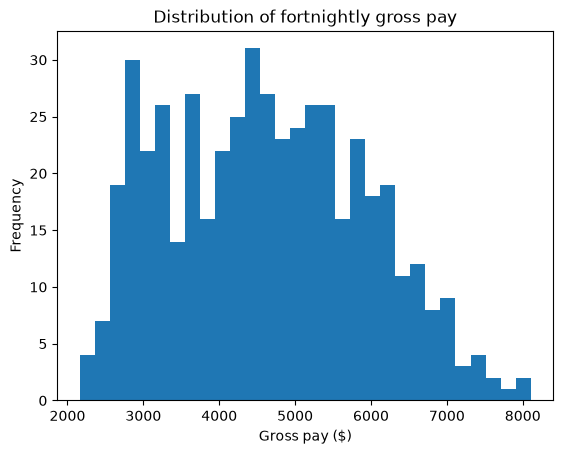

In [2]:
audit["gross_pay"].plot.hist(bins=30, title="Distribution of fortnightly gross pay")
plt.xlabel("Gross pay ($)")
plt.show()


## Rejected records (this shows what the validation caught)

In [3]:
rejected

,employee_id,hourly_rate,hours_worked
0,E0011,51.65,-5.0
1,E0078,67.08,-5.0
2,E0151,NaN,93.3


In [4]:
sql_total = pd.read_sql("SELECT ROUND(SUM(gross_pay), 2) AS total FROM calc_audit", con).iloc[0, 0]
print(f"Total gross pay from SQL: ${sql_total:,.2f}")
print(f"Total gross pay from pandas: ${audit['gross_pay'].sum():,.2f}")

Total gross pay from SQL: $2,298,619.19
Total gross pay from pandas: $2,298,619.19
